# BÀI THỰC HÀNH CHƯƠNG 1 — XỬ LÝ ẢNH BẰNG PYTHON

**Thư viện:** OpenCV, Pillow, NumPy và Matplotlib.  
**Mục tiêu:** đọc/hiển thị/lưu ảnh, chuyển không gian màu, cắt và thay đổi kích thước, vẽ hình và thêm văn bản.

### Cách sử dụng
1. Chọn kernel Python rồi chạy lần lượt từ trên xuống (**Run All**).
2. Notebook tự tạo ảnh mẫu trên máy nếu chưa có. Để dùng ảnh cá nhân, sửa `IMAGE_PATH` ở phần 2 thành đường dẫn ảnh của bạn.
3. Ảnh kết quả nằm trong thư mục `ket_qua` của thư mục làm việc. Các hình đã hiển thị được lưu ngay trong notebook.

Ảnh mẫu là hình minh họa tạo bằng mã để bài chạy độc lập, không cần tải ảnh từ Internet. Khi dùng ảnh riêng, nên chọn ảnh có chiều rộng và chiều cao từ 100 pixel trở lên để quan sát rõ.

## 1. Cài đặt thư viện
`opencv-python` cung cấp `cv2`; `Pillow` cung cấp `PIL`. NumPy xử lý mảng pixel, Matplotlib hiển thị ảnh trong notebook.

Cell dưới kiểm tra và chỉ cài những thư viện còn thiếu bằng đúng Python của kernel. Lần cài đầu cần kết nối Internet. Nếu Jupyter yêu cầu, khởi động lại kernel sau khi cài rồi chạy lại. Có thể cài thủ công bằng `%pip install opencv-python Pillow numpy matplotlib`.

In [1]:
import importlib.util
import subprocess
import sys

packages = {"cv2": "opencv-python", "PIL": "Pillow", "numpy": "numpy", "matplotlib": "matplotlib"}
missing = [package for module, package in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
else:
    print("Đã có đủ các thư viện cần thiết.")

Đã có đủ các thư viện cần thiết.


In [2]:
from pathlib import Path
import cv2
import PIL
from PIL import Image, ImageDraw, ImageFont, ImageOps
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

OUTPUT_DIR = Path("ket_qua")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
print("Python:", sys.version.split()[0])
print("OpenCV:", cv2.__version__, "| Pillow:", PIL.__version__)
print("Thư mục làm việc:", Path.cwd())

def show_images(images, titles, cmaps=None, cols=3):
    """Hiển thị ảnh RGB hoặc ảnh một kênh; không tự diễn giải mảng BGR/HSV/LAB."""
    rows = (len(images) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 3.7 * rows), squeeze=False)
    cmaps = cmaps or [None] * len(images)
    for ax, img, title, cmap in zip(axes.flat, images, titles, cmaps):
        ax.imshow(img, cmap=cmap, vmin=0 if cmap == "gray" else None,
                  vmax=255 if cmap == "gray" else None)
        ax.set_title(title)
        ax.axis("off")
    for ax in list(axes.flat)[len(images):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()


def save_cv(filename, array):
    """Mã hóa ảnh OpenCV và lưu; hỗ trợ đường dẫn có dấu qua pathlib."""
    path = OUTPUT_DIR / filename
    success, encoded = cv2.imencode(path.suffix, array)
    if not success:
        raise OSError(f"Không mã hóa được ảnh: {path}")
    path.write_bytes(encoded.tobytes())
    return path

Python: 3.14.7
OpenCV: 5.0.0 | Pillow: 13.0.0
Thư mục làm việc: /Users/mac/Documents/Edu/nam_ba/ComputerVision/CV_Labs/Lab1


## 2. Đọc, hiển thị và lưu ảnh
### 2.1. Chuẩn bị ảnh trên máy
Ảnh mẫu có các vùng màu và chi tiết hình học giúp dễ quan sát chuyển đổi màu, cắt ảnh và nội suy. Cell chỉ tạo ảnh mẫu nếu tệp chưa tồn tại.

In [3]:
SAMPLE_PATH = Path("du_lieu/anh_mau.png")
SAMPLE_PATH.parent.mkdir(parents=True, exist_ok=True)
if not SAMPLE_PATH.exists():
    sample = Image.new("RGB", (960, 640), "#d5efff")
    draw = ImageDraw.Draw(sample)
    for y in range(640):
        t = y / 639
        draw.line([(0, y), (959, y)], fill=(int(110 + 110*t), int(185 + 55*t), 250))
    draw.ellipse((690, 55, 825, 190), fill="#ffd34d")
    draw.polygon([(0, 430), (220, 165), (460, 440)], fill="#567d8a")
    draw.polygon([(250, 450), (550, 205), (810, 450)], fill="#759c83")
    draw.rectangle((0, 430, 960, 640), fill="#75b85c")
    draw.rectangle((345, 355, 585, 540), fill="#ffe0a3")
    draw.polygon([(315, 360), (465, 235), (615, 360)], fill="#cf5549")
    draw.rectangle((440, 420, 500, 540), fill="#785240")
    draw.rectangle((365, 390, 415, 440), fill="#6ec7ee", outline="white", width=5)
    draw.rectangle((520, 390, 570, 440), fill="#6ec7ee", outline="white", width=5)
    draw.rectangle((150, 360, 175, 540), fill="#7b5233")
    draw.ellipse((75, 260, 255, 425), fill="#27864d")
    for i, color in enumerate(["#ed4242", "#36b75c", "#326fe0", "#f9d343", "#df63c8"]):
        draw.rectangle((650+i*55, 545, 690+i*55, 600), fill=color)
    sample.save(SAMPLE_PATH)

# THAY ĐƯỜNG DẪN NÀY nếu muốn dùng ảnh của bạn.
# Ví dụ Windows: Path(r"C:\Users\YourName\Pictures\anh.jpg")
# Ví dụ macOS: Path("/Users/yourname/Pictures/anh.jpg")
IMAGE_PATH = SAMPLE_PATH
if not IMAGE_PATH.is_file():
    raise FileNotFoundError(f"Không tìm thấy ảnh: {IMAGE_PATH.resolve()}")
print("Ảnh đầu vào:", IMAGE_PATH.resolve())

Ảnh đầu vào: /Users/mac/Documents/Edu/nam_ba/ComputerVision/CV_Labs/Lab1/du_lieu/anh_mau.png


### 2.2. Đọc bằng OpenCV và Pillow
- OpenCV đọc ảnh màu theo thứ tự **BGR**; Matplotlib và Pillow thường dùng **RGB**. Phải đổi BGR → RGB trước khi hiển thị bằng Matplotlib.
- `cv2.imdecode` đọc dữ liệu tệp tương tự `cv2.imread`, đồng thời thuận tiện với đường dẫn Unicode.
- Pillow dùng `ImageOps.exif_transpose` để áp dụng hướng ảnh EXIF. Bài chuyển ảnh về 3 kênh RGB, không giữ kênh alpha của ảnh trong suốt.
- Kích thước mảng NumPy là `(cao, rộng, kênh)`; `Pillow.size` là `(rộng, cao)`.

Định dạng gốc: PNG
Rộng: 960, cao: 640, số kênh: 3
Kiểu dữ liệu: uint8; dung lượng mảng: 1,843,200 byte
Kích thước Pillow: (960, 640)


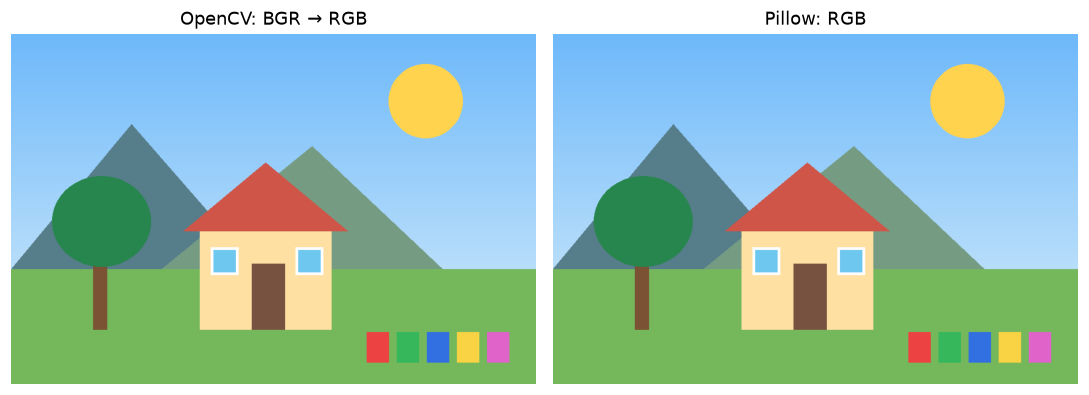

In [4]:
raw_bytes = np.frombuffer(IMAGE_PATH.read_bytes(), dtype=np.uint8)
img_bgr = cv2.imdecode(raw_bytes, cv2.IMREAD_COLOR)
if img_bgr is None:
    raise ValueError("Không giải mã được ảnh. Hãy kiểm tra nội dung và định dạng tệp.")
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
with Image.open(IMAGE_PATH) as source:
    source_format = source.format
    img_pil = ImageOps.exif_transpose(source).convert("RGB")
height, width = img_rgb.shape[:2]
if min(height, width) < 4:
    raise ValueError("Hãy chọn ảnh có cả hai chiều từ 4 pixel trở lên.")
print(f"Định dạng gốc: {source_format}")
print(f"Rộng: {width}, cao: {height}, số kênh: {img_rgb.shape[2]}")
print(f"Kiểu dữ liệu: {img_rgb.dtype}; dung lượng mảng: {img_rgb.nbytes:,} byte")
print("Kích thước Pillow:", img_pil.size)
show_images([img_rgb, img_pil], ["OpenCV: BGR → RGB", "Pillow: RGB"], cols=2)

### 2.3. Lưu ảnh với định dạng khác
Lưu ra PNG (không mất dữ liệu), JPEG (nén mất dữ liệu) và BMP. Như vậy luôn có định dạng khác ảnh đầu vào. OpenCV nhận mảng BGR khi lưu ảnh màu. JPEG không hỗ trợ alpha; chất lượng 95 vẫn có thể làm thay đổi pixel.

In [5]:
save_cv("01_anh_doc_opencv.png", img_bgr)
img_pil.save(OUTPUT_DIR / "01_anh_doi_dinh_dang.jpg", quality=95)
img_pil.save(OUTPUT_DIR / "01_anh_doi_dinh_dang.bmp")
print("Đã lưu ảnh PNG, JPEG và BMP vào", OUTPUT_DIR.resolve())

Đã lưu ảnh PNG, JPEG và BMP vào /Users/mac/Documents/Edu/nam_ba/ComputerVision/CV_Labs/Lab1/ket_qua


## 3. Chuyển đổi không gian màu
### 3.1. RGB → Grayscale
Ảnh xám có một kênh cường độ. Công thức gần đúng: **Y = 0.299R + 0.587G + 0.114B**. Đây là tổng có trọng số, không phải trung bình cộng ba kênh. OpenCV và Pillow có thể khác 1 mức xám do làm tròn.

Shape ảnh màu: (640, 960, 3) | Shape ảnh xám: (640, 960)


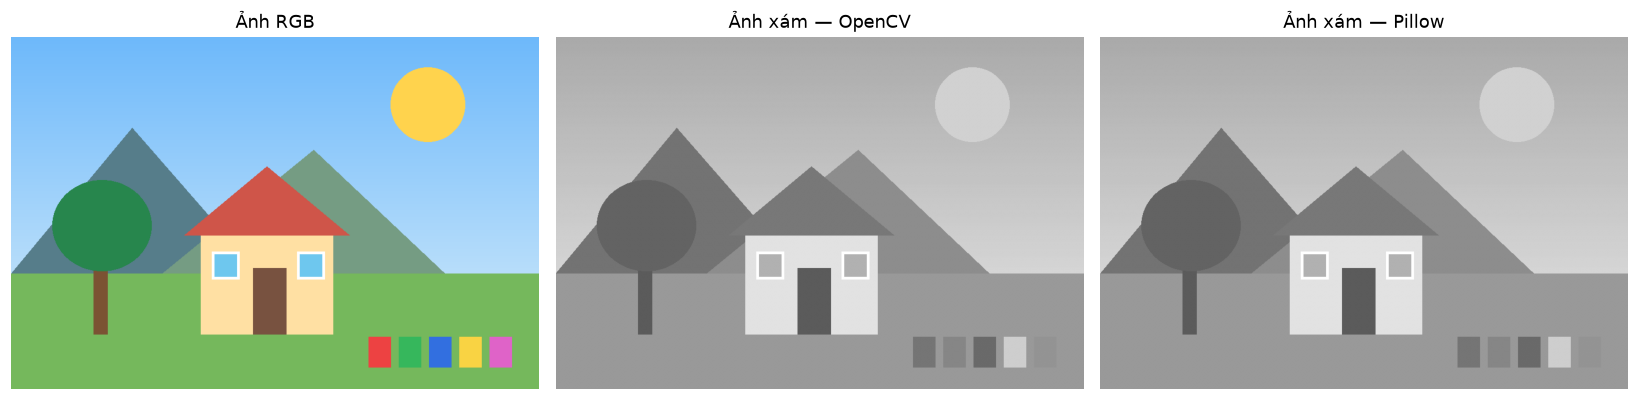

In [6]:
gray_cv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
gray_pil = img_pil.convert("L")
print("Shape ảnh màu:", img_rgb.shape, "| Shape ảnh xám:", gray_cv.shape)
show_images([img_rgb, gray_cv, gray_pil], ["Ảnh RGB", "Ảnh xám — OpenCV", "Ảnh xám — Pillow"], [None, "gray", "gray"])
save_cv("02_grayscale.png", gray_cv)
gray_pil.save(OUTPUT_DIR / "02_grayscale_pillow.png")

### 3.2. RGB → HSV
HSV biểu diễn **H** (sắc màu), **S** (độ bão hòa), **V** (độ sáng theo giá trị kênh lớn nhất).
Với ảnh `uint8` và phép đổi thông thường của OpenCV: H thuộc **0–179** (xấp xỉ góc màu chia 2), S và V thuộc **0–255**. Khi S bằng 0, sắc màu không có ý nghĩa.

Không hiển thị trực tiếp mảng HSV như RGB vì sẽ ra màu sai. Dưới đây hiển thị riêng từng kênh; bảng màu ở kênh H chỉ hỗ trợ quan sát.

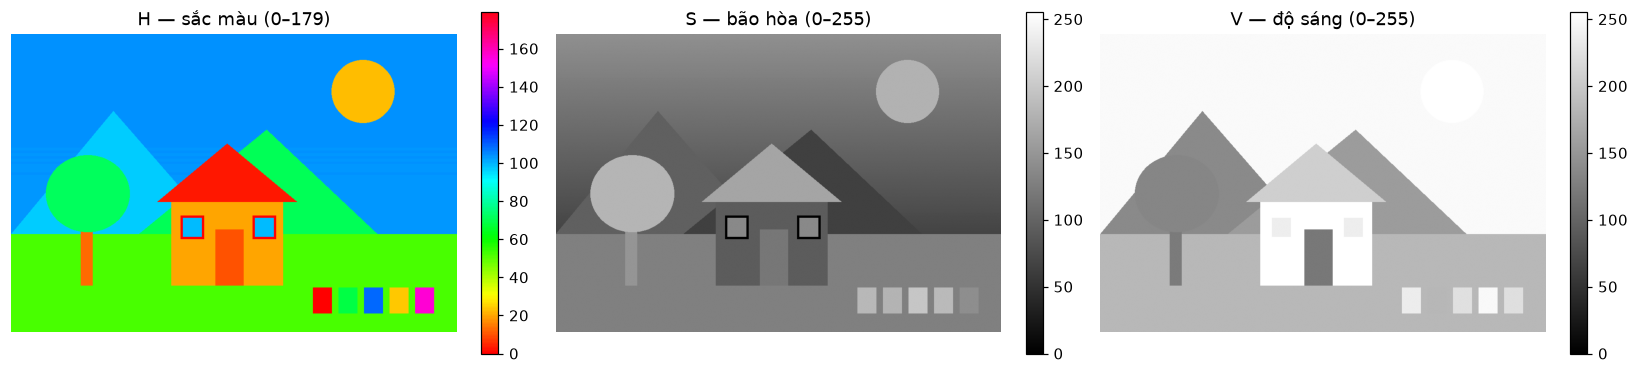

In [7]:
hsv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)
h_channel, s_channel, v_channel = cv2.split(hsv)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, channel, title, cmap, upper in zip(
    axes, [h_channel, s_channel, v_channel],
    ["H — sắc màu (0–179)", "S — bão hòa (0–255)", "V — độ sáng (0–255)"],
    ["hsv", "gray", "gray"], [179, 255, 255]
):
    plot = ax.imshow(channel, cmap=cmap, vmin=0, vmax=upper)
    ax.set_title(title)
    ax.axis("off")
    fig.colorbar(plot, ax=ax, fraction=0.035)
plt.tight_layout()
plt.show()
np.save(OUTPUT_DIR / "03_hsv.npy", hsv)
for name, channel in zip(["H", "S", "V"], cv2.split(hsv)):
    save_cv(f"03_HSV_kenh_{name}.png", channel)

### 3.3. RGB → CIELAB (LAB)
CIELAB gồm **L\*** (độ sáng), **a\*** (trục xanh lá ↔ đỏ), **b\*** (trục xanh dương ↔ vàng).
Với mã hóa `uint8` của OpenCV, cả ba kênh nằm trong 0–255: `L* ≈ L8 × 100/255`, `a* ≈ a8 − 128`, `b* ≈ b8 − 128`. Giá trị a8/b8 gần 128 biểu diễn vùng trung tính.

Các ảnh kênh dưới đây dùng thang xám để quan sát giá trị mã hóa, không phải màu sắc gốc. Tệp `.npy` giữ đúng dữ liệu HSV/LAB để đọc lại bằng `np.load`.

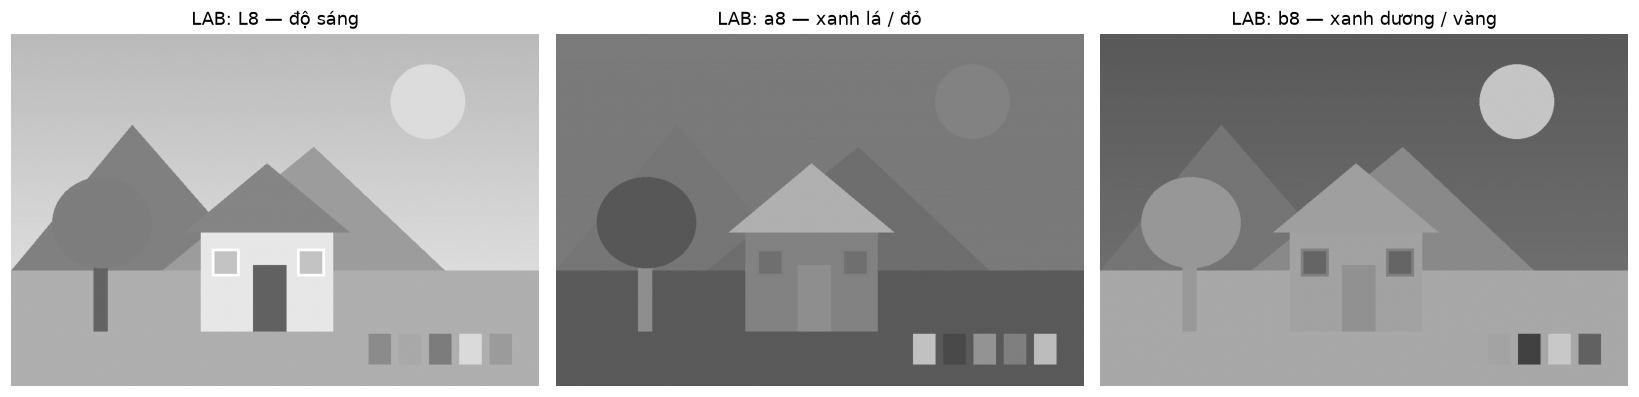

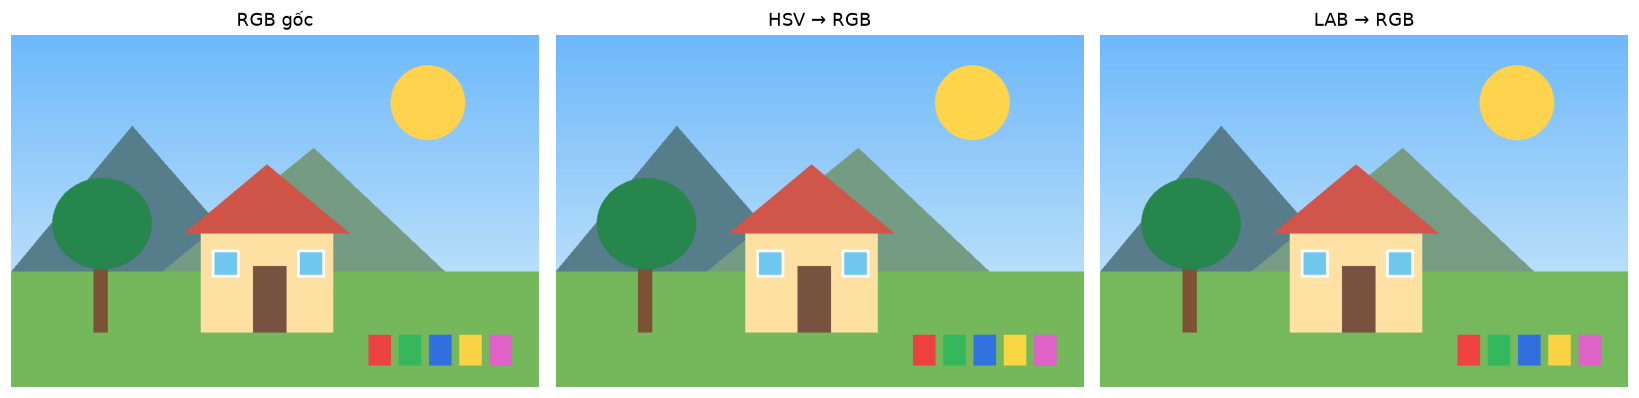

HSV → RGB: sai số tuyệt đối trung bình = 0.513; lớn nhất = 2
LAB → RGB: sai số tuyệt đối trung bình = 0.463; lớn nhất = 3


In [8]:
lab = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2LAB)
l_channel, a_channel, b_channel = cv2.split(lab)
show_images([l_channel, a_channel, b_channel],
            ["LAB: L8 — độ sáng", "LAB: a8 — xanh lá / đỏ", "LAB: b8 — xanh dương / vàng"],
            ["gray", "gray", "gray"])
np.save(OUTPUT_DIR / "04_lab.npy", lab)
for name, channel in zip(["L", "a", "b"], cv2.split(lab)):
    save_cv(f"04_LAB_kenh_{name}.png", channel)
rgb_from_hsv = cv2.cvtColor(hsv, cv2.COLOR_HSV2RGB)
rgb_from_lab = cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)
show_images([img_rgb, rgb_from_hsv, rgb_from_lab],
            ["RGB gốc", "HSV → RGB", "LAB → RGB"])
for name, restored in [("HSV", rgb_from_hsv), ("LAB", rgb_from_lab)]:
    error = np.abs(img_rgb.astype(np.int16) - restored.astype(np.int16))
    print(f"{name} → RGB: sai số tuyệt đối trung bình = {error.mean():.3f}; lớn nhất = {error.max()}")

**Nhận xét:** chuyển đổi màu rồi chuyển ngược có thể không khôi phục chính xác mọi pixel do lượng tử hóa 8 bit và làm tròn. Phải ép kiểu sang số nguyên có dấu trước khi trừ để tránh tràn số `uint8`.

## 4. Cắt xén và thay đổi kích thước
### 4.1. Cắt một vùng ảnh
Gốc tọa độ ở góc trên trái; x tăng sang phải, y tăng xuống dưới. NumPy cắt bằng `image[y1:y2, x1:x2]`; Pillow dùng hộp `(x1, y1, x2, y2)`. Cạnh phải và dưới không được lấy vào kết quả.

Ví dụ chọn vùng từ 25% đến 75% chiều rộng, 20% đến 85% chiều cao. Dùng tỷ lệ giúp ví dụ áp dụng được với nhiều kích thước ảnh.

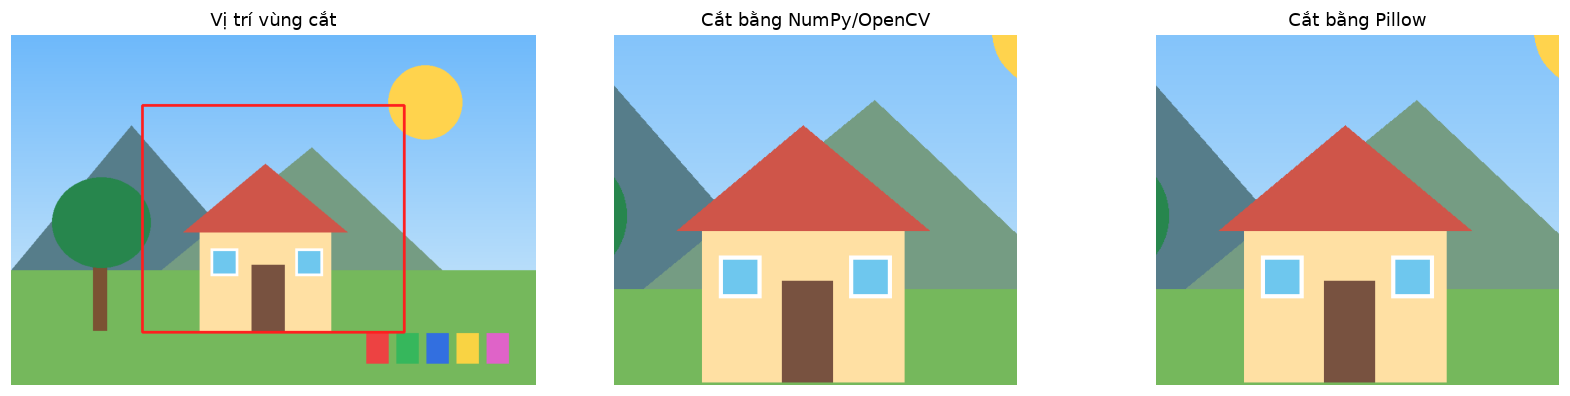

Hộp cắt: (240, 128, 720, 544); kích thước: 480 × 416


PosixPath('ket_qua/05_crop.png')

In [9]:
x1, x2 = int(width * 0.25), int(width * 0.75)
y1, y2 = int(height * 0.20), int(height * 0.85)
assert 0 <= x1 < x2 <= width and 0 <= y1 < y2 <= height
cropped = img_rgb[y1:y2, x1:x2].copy()
# Dùng cùng dữ liệu RGB để so sánh chính xác hai cách cắt.
cropped_pil = Image.fromarray(img_rgb).crop((x1, y1, x2, y2))
marked = img_rgb.copy()
cv2.rectangle(marked, (x1, y1), (x2-1, y2-1), (255, 30, 30), max(1, min(height, width)//150))
show_images([marked, cropped, cropped_pil],
            ["Vị trí vùng cắt", "Cắt bằng NumPy/OpenCV", "Cắt bằng Pillow"])
print(f"Hộp cắt: ({x1}, {y1}, {x2}, {y2}); kích thước: {x2-x1} × {y2-y1}")
save_cv("05_crop.png", cv2.cvtColor(cropped, cv2.COLOR_RGB2BGR))

### 4.2. Đổi kích thước theo tỷ lệ và kích thước cố định
- Thu nhỏ 50%: giữ gần đúng tỷ lệ ảnh, có sai lệch rất nhỏ do làm tròn số pixel. Dùng `INTER_AREA` phù hợp khi thu nhỏ.
- Ép về 400 × 300: đúng kích thước nhưng có thể làm méo hình nếu tỷ lệ ảnh gốc khác 4:3. Dùng `INTER_LINEAR` cho ví dụ này.
- Pillow `ImageOps.pad`: giữ tỷ lệ, thêm viền để đạt đúng 400 × 300; `LANCZOS` là bộ lọc nội suy chất lượng cao.

Lưu ý `cv2.resize` nhận `dsize=(rộng, cao)`, trái với thứ tự hai chiều đầu của mảng.

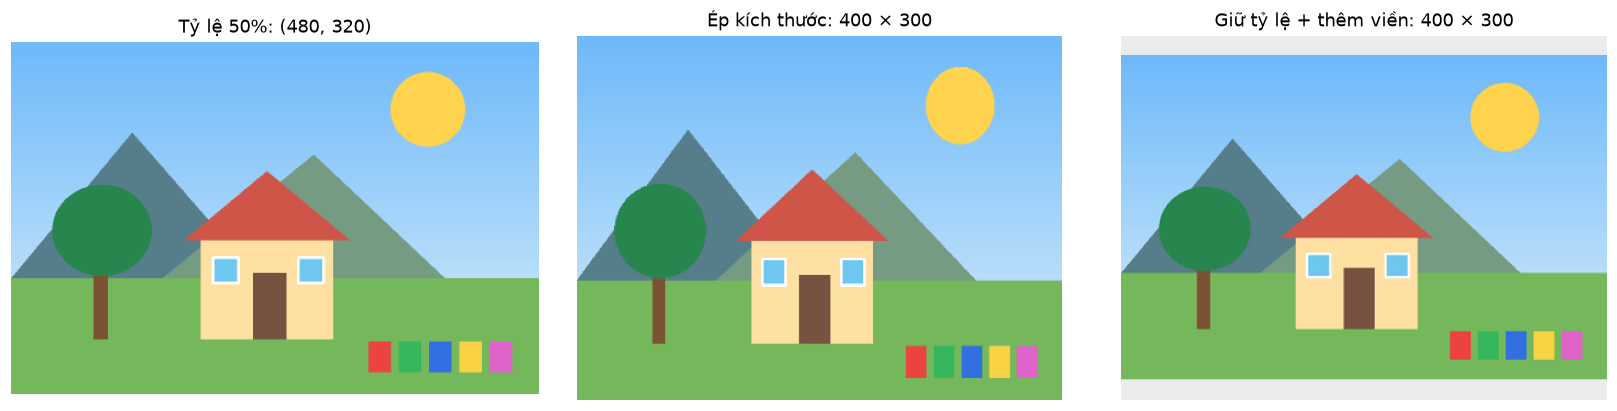

Kích thước mảng sau thu nhỏ: (320, 480, 3)


In [10]:
scale = 0.5
scaled_size = (max(1, round(width * scale)), max(1, round(height * scale)))
resized_scale = cv2.resize(img_rgb, scaled_size, interpolation=cv2.INTER_AREA)
fixed_size = (400, 300)
resized_fixed = cv2.resize(img_rgb, fixed_size, interpolation=cv2.INTER_LINEAR)
resized_pad = ImageOps.pad(Image.fromarray(img_rgb), fixed_size,
                           method=Image.Resampling.LANCZOS, color=(235, 235, 235))
show_images([resized_scale, resized_fixed, resized_pad],
            [f"Tỷ lệ 50%: {scaled_size}", "Ép kích thước: 400 × 300", "Giữ tỷ lệ + thêm viền: 400 × 300"])
for name, value in [("06_resize_50_percent.png", resized_scale), ("06_resize_fixed.png", resized_fixed)]:
    save_cv(name, cv2.cvtColor(value, cv2.COLOR_RGB2BGR))
resized_pad.save(OUTPUT_DIR / "06_resize_padded.png")
print("Kích thước mảng sau thu nhỏ:", resized_scale.shape)

## 5. Vẽ hình cơ bản và thêm văn bản
### 5.1. OpenCV: đường thẳng, hình chữ nhật, hình tròn, chữ
Vẽ trên bản sao BGR để không thay đổi ảnh gốc. Màu OpenCV ở đây là `(B, G, R)`; độ dày `-1` sẽ tô kín hình. `LINE_AA` làm mượt đường biên. Tọa độ được tính theo tỷ lệ ảnh.

`cv2.putText` với font Hershey thông thường không hỗ trợ đầy đủ tiếng Việt, nên ví dụ dùng chữ không dấu. Pillow ở phần sau minh họa cách chèn tiếng Việt khi có font Unicode.

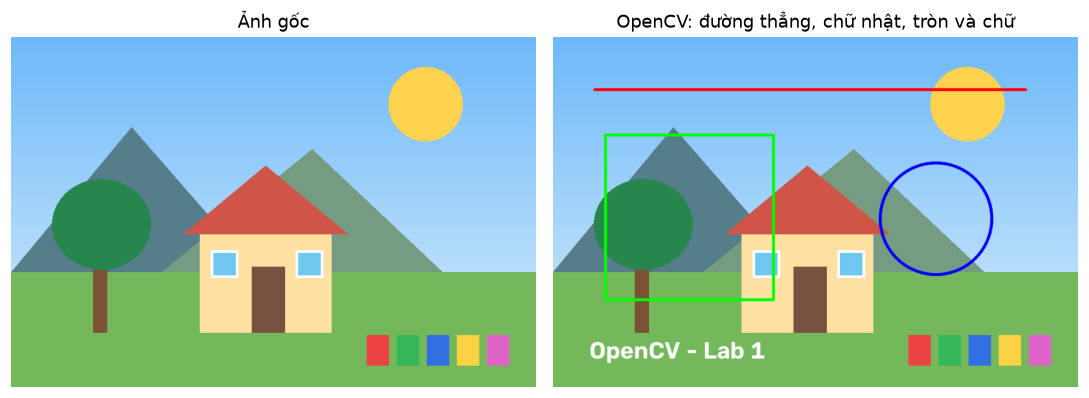

PosixPath('ket_qua/07_ve_hinh_opencv.png')

In [11]:
drawn_bgr = img_bgr.copy()
thickness = max(1, round(min(width, height) / 180))
def point(x_fraction, y_fraction):
    return (min(width-1, int(width*x_fraction)), min(height-1, int(height*y_fraction)))

cv2.line(drawn_bgr, point(0.08, 0.15), point(0.90, 0.15), (0, 0, 255), thickness, cv2.LINE_AA)
cv2.rectangle(drawn_bgr, point(0.10, 0.28), point(0.42, 0.75), (0, 255, 0), thickness, cv2.LINE_AA)
cv2.circle(drawn_bgr, point(0.73, 0.52), max(1, int(min(width, height)*0.16)),
           (255, 0, 0), thickness, cv2.LINE_AA)
text = "OpenCV - Lab 1"
font_scale = max(0.1, min(width/650, height/350))
(text_width, _), _ = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, font_scale, thickness)
if text_width > width * 0.86:
    font_scale *= width * 0.86 / text_width
cv2.putText(drawn_bgr, text, point(0.07, 0.92), cv2.FONT_HERSHEY_SIMPLEX,
            font_scale, (255, 255, 255), thickness, cv2.LINE_AA)
show_images([img_rgb, cv2.cvtColor(drawn_bgr, cv2.COLOR_BGR2RGB)],
            ["Ảnh gốc", "OpenCV: đường thẳng, chữ nhật, tròn và chữ"], cols=2)
save_cv("07_ve_hinh_opencv.png", drawn_bgr)

### 5.2. Pillow: vẽ và chèn chữ tiếng Việt
Pillow vẽ bằng màu RGB. Ví dụ tìm font DejaVu Sans đi kèm Matplotlib (hỗ trợ tiếng Việt). Khung nền giúp chữ dễ đọc. Cỡ chữ tự điều chỉnh theo ảnh; ảnh quá nhỏ vẫn có thể khó đọc.

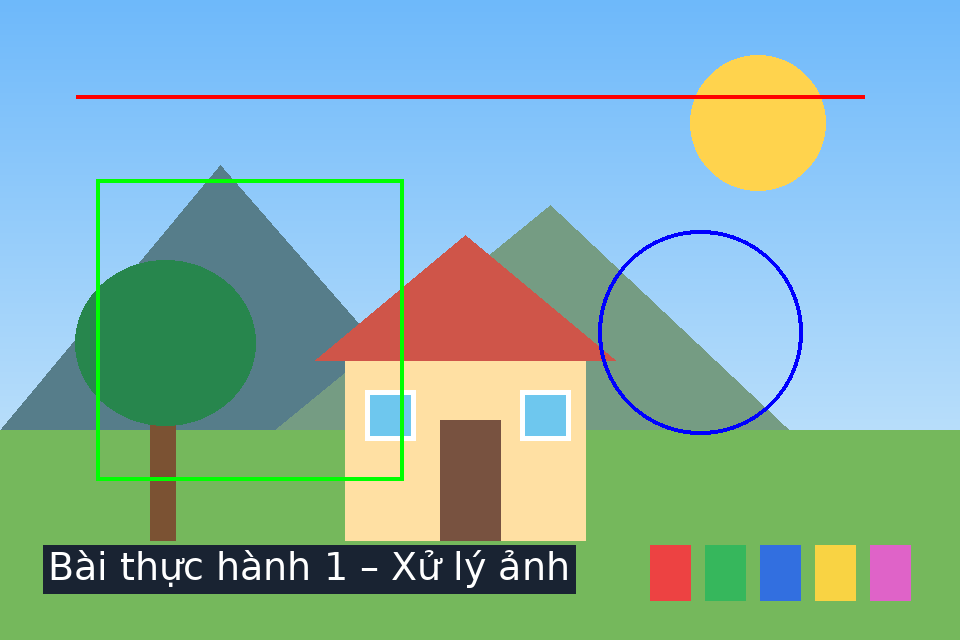

Đã lưu ảnh vẽ bằng Pillow.


In [12]:
from matplotlib import font_manager

pillow_drawn = Image.fromarray(img_rgb).copy()
painter = ImageDraw.Draw(pillow_drawn)
painter.line([point(0.08, 0.15), point(0.90, 0.15)], fill=(255, 0, 0), width=thickness)
painter.rectangle([point(0.10, 0.28), point(0.42, 0.75)], outline=(0, 255, 0), width=thickness)
cx, cy = point(0.73, 0.52)
radius = max(1, int(min(width, height)*0.16))
painter.ellipse((cx-radius, cy-radius, cx+radius, cy+radius), outline=(0, 0, 255), width=thickness)
font_path = font_manager.findfont("DejaVu Sans")
label = "Bài thực hành 1 – Xử lý ảnh"
font_size = max(1, int(min(width / 25, height / 15)))
font = ImageFont.truetype(font_path, font_size)
while painter.textbbox((0, 0), label, font=font)[2] > width * 0.88 and font_size > 1:
    font_size -= 1
    font = ImageFont.truetype(font_path, font_size)
tx, ty = point(0.05, 0.85)
bbox = painter.textbbox((tx, ty), label, font=font)
padding = max(1, int(min(width, height)*0.008))
painter.rectangle((bbox[0]-padding, bbox[1]-padding, bbox[2]+padding, bbox[3]+padding), fill=(25, 35, 50))
painter.text((tx, ty), label, font=font, fill=(255, 255, 255))
display(pillow_drawn)
pillow_drawn.save(OUTPUT_DIR / "08_ve_hinh_pillow.png")
print("Đã lưu ảnh vẽ bằng Pillow.")

## 6. Kiểm tra kết quả
Các kiểm tra sau xác nhận kích thước, kiểu dữ liệu, hai cách cắt tương đương, dữ liệu màu lưu đúng và ảnh PNG đọc lại không thay đổi pixel. Không yêu cầu ảnh JPEG hay phép đổi HSV/LAB khôi phục chính xác vì có nén/làm tròn.

In [13]:
assert img_rgb.dtype == np.uint8 and img_rgb.shape[2] == 3
assert gray_cv.shape == (height, width)
assert hsv.shape == lab.shape == img_rgb.shape
assert h_channel.max() <= 179
assert cropped.shape[:2] == (y2-y1, x2-x1)
assert np.array_equal(cropped, np.asarray(cropped_pil))
assert resized_scale.shape[:2] == (scaled_size[1], scaled_size[0])
assert resized_fixed.shape[:2] == (300, 400)
assert resized_pad.size == (400, 300)
assert np.array_equal(np.load(OUTPUT_DIR / "03_hsv.npy"), hsv)
assert np.array_equal(np.load(OUTPUT_DIR / "04_lab.npy"), lab)
restored_png = cv2.imdecode(np.frombuffer((OUTPUT_DIR / "01_anh_doc_opencv.png").read_bytes(), np.uint8), cv2.IMREAD_COLOR)
assert np.array_equal(restored_png, img_bgr)
assert np.array_equal(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB), img_rgb), "Ảnh gốc đã bị sửa."
for path in sorted(OUTPUT_DIR.iterdir()):
    if path.suffix.lower() in {".png", ".jpg", ".bmp"}:
        with Image.open(path) as check:
            check.load()
            print(f"{path.name:32} {str(check.size):14} {path.stat().st_size:>9,} byte")
print("\nĐẠT: tất cả kiểm tra đã thành công.")

01_anh_doc_opencv.png            (960, 640)        20,406 byte
01_anh_doi_dinh_dang.bmp         (960, 640)     1,843,254 byte


01_anh_doi_dinh_dang.jpg         (960, 640)        46,790 byte
02_grayscale.png                 (960, 640)        10,949 byte
02_grayscale_pillow.png          (960, 640)         5,516 byte
03_HSV_kenh_H.png                (960, 640)        10,368 byte
03_HSV_kenh_S.png                (960, 640)        11,059 byte
03_HSV_kenh_V.png                (960, 640)         9,801 byte
04_LAB_kenh_L.png                (960, 640)        10,913 byte
04_LAB_kenh_a.png                (960, 640)        10,414 byte
04_LAB_kenh_b.png                (960, 640)        10,746 byte
05_crop.png                      (480, 416)        10,507 byte
06_resize_50_percent.png         (480, 320)        13,493 byte
06_resize_fixed.png              (400, 300)        12,192 byte
06_resize_padded.png             (400, 300)        14,912 byte
07_ve_hinh_opencv.png            (960, 640)        47,627 byte
08_ve_hinh_pillow.png            (960, 640)        16,550 byte

ĐẠT: tất cả kiểm tra đã thành công.


## 7. Tổng kết và lưu ý

| Yêu cầu trong đề | Nội dung đã thực hiện |
|---|---|
| Cài OpenCV, Pillow | Kiểm tra/cài thư viện, in phiên bản |
| Đọc và hiển thị ảnh | Đọc ảnh trên máy bằng hai thư viện, hiển thị ngay trong notebook |
| Lưu định dạng khác | PNG, JPEG, BMP và các ảnh sau xử lý |
| Chuyển màu | RGB → grayscale, HSV, LAB; tách kênh và chuyển ngược |
| Cắt xén | Cắt theo tọa độ bằng NumPy và Pillow, đánh dấu vùng cắt |
| Thay đổi kích thước | Theo tỷ lệ, kích thước cố định, giữ tỷ lệ có viền |
| Vẽ hình và thêm chữ | Đường thẳng, chữ nhật, hình tròn, chữ bằng OpenCV và Pillow |

**Các lỗi thường gặp:**
- Ảnh bị đảo đỏ/xanh: đã đưa BGR vào nơi yêu cầu RGB.
- Cắt sai vùng: đã nhầm `[y, x]` thành `[x, y]`.
- Ảnh bị kéo méo: ép kích thước mới không cùng tỷ lệ ảnh gốc.
- Ảnh xám trông có màu: chưa chọn `cmap="gray"`.
- Không đọc được ảnh: kiểm tra đường dẫn và nội dung tệp, không chỉ phần mở rộng.

Notebook sử dụng Matplotlib/Pillow thay cho `cv2.imshow`, phù hợp với Jupyter và môi trường không có cửa sổ giao diện. Sau khi thay ảnh đầu vào, chạy lại toàn bộ để cập nhật các kết quả; tệp kết quả trùng tên sẽ được ghi đè.